# 01 · Preprocessing — Kürten 2021 HNSCC (malignant compartment)

Isolate malignant cells, threshold thin samples by a **data-driven multiplicative
gap**, integrate patients (Harmony), embed, remove detached islands, and split the
manifold into its two transcriptional compartments. Unlike Puram 2017 (which
resolves four HNSCC subtypes radiating from a central *Mixed* hub), the Kürten
malignant manifold separates into a **cycling/metabolic** lobe and an
**embryonic-program** lobe; the latter carries the gastrulation/somitogenesis/
neural-crest axis analysed in 02–04. Every tunable choice is *derived from this
dataset*, not inherited. Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)        # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)  # h5ads
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Kürten2021_Head-and-Neck | category: Head-and-Neck


### Load malignant compartment
Kürten et al. annotate cell type directly; we take their `Malignant` calls.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())

Loading ../../../../../../data/unzip/CCCA/Data_Kürten2021_Head-and-Neck
/home/caleb/miniconda3/envs/scFates/lib/python3.11/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
Done.
full atlas: (62700, 33545)
malignant: (11400, 33545) | samples: 20


### Sample thresholding — derived by multiplicative gap-finding
Per-sample malignant counts are dominated by CD45⁺-sorted fractions that contain
only spillover tumour cells. Rather than a round-number cut, we find the largest
**multiplicative** cliff in the sorted counts and cut at its geometric mean — this
is the natural separatrix between real tumour-bearing samples and spillover.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values)
print(f'largest gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [2458 2256 1254 1096 1036 1032  807  807  376   89   43   36   36   22
   21   10    9    5    5    2]
largest gap: 376 -> 89 (ratio 4.22)
derived threshold (geometric mean across the gap) = 182
kept 9/20 samples -> 11122 cells


### Overdispersion, PCA, Harmony integration, embedding
Harmony `theta=10` was selected by a same-sample-neighbour-fraction sweep (theta 2/5/10): theta=10 gives the strongest batch mixing without collapsing biology.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
sce.pp.harmony_integrate(adata, 'sample', theta=10, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1546 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1546
2026-07-27 23:17:42,137 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-07-27 23:17:43,467 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-07-27 23:17:43,528 - harmonypy - INFO - Iteration 1 of 30
2026-07-27 23:17:45,993 - harmonypy - INFO - Iteration 2 of 30
2026-07-27 23:17:48,713 - harmonypy - INFO - Iteration 3 of 30
2026-07-27 23:17:51,169 - harmonypy - INFO - Iteration 4 of 30
2026-07-27 23:17:52,229 - harmonypy - INFO - Iteration 5 of 30
2026-07-27 23:17:54,248 - harmonypy - INFO - Iteration 6 of 30
2026-07-27 23:17:55,784 - harmonypy - INFO - Iteration 7 of 

### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and
drop any cell outside the main connected component — stripping physically
detached specks while keeping the continuous arm termini.

In [6]:
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()

removed 0 cells in 0 detached islands


### Compartment split + labelling (data-driven)
Low-resolution Leiden (res=0.15) recovers two lobes. We label them *by biology*,
not by Leiden index: the compartment with the **lower cycling fraction** is the
**Embryonic** lobe (it carries the developmental modules); the other is
**Cycling/Metabolic**. `cell_cycle_phase` comes from the loader's phase calls.

In [7]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
emb_lobe = cyc.idxmin()
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', cyc.round(2).to_dict())
lab_map = {l: ('Embryonic' if l==emb_lobe else 'Cycling/Metabolic')
           for l in adata.obs['lobe'].cat.categories}
adata.obs['compartment'] = adata.obs['lobe'].map(lab_map).astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

lobe sizes: {'1': 5955, '0': 5167}
cycling fraction per lobe: {'0': 0.46, '1': 0.22}
compartments: {'Embryonic': 5955, 'Cycling/Metabolic': 5167}


### Gate 1 — batch mixing & manifold continuity
Samples must intermix (no per-patient islands) on one continuous manifold.
Visual inspection below; the deliverable `samples.pdf` follows.

9 samples share one continuous manifold; both compartments contain multiple samples.
Gate 1: samples intermixed on one continuous manifold -> PASS


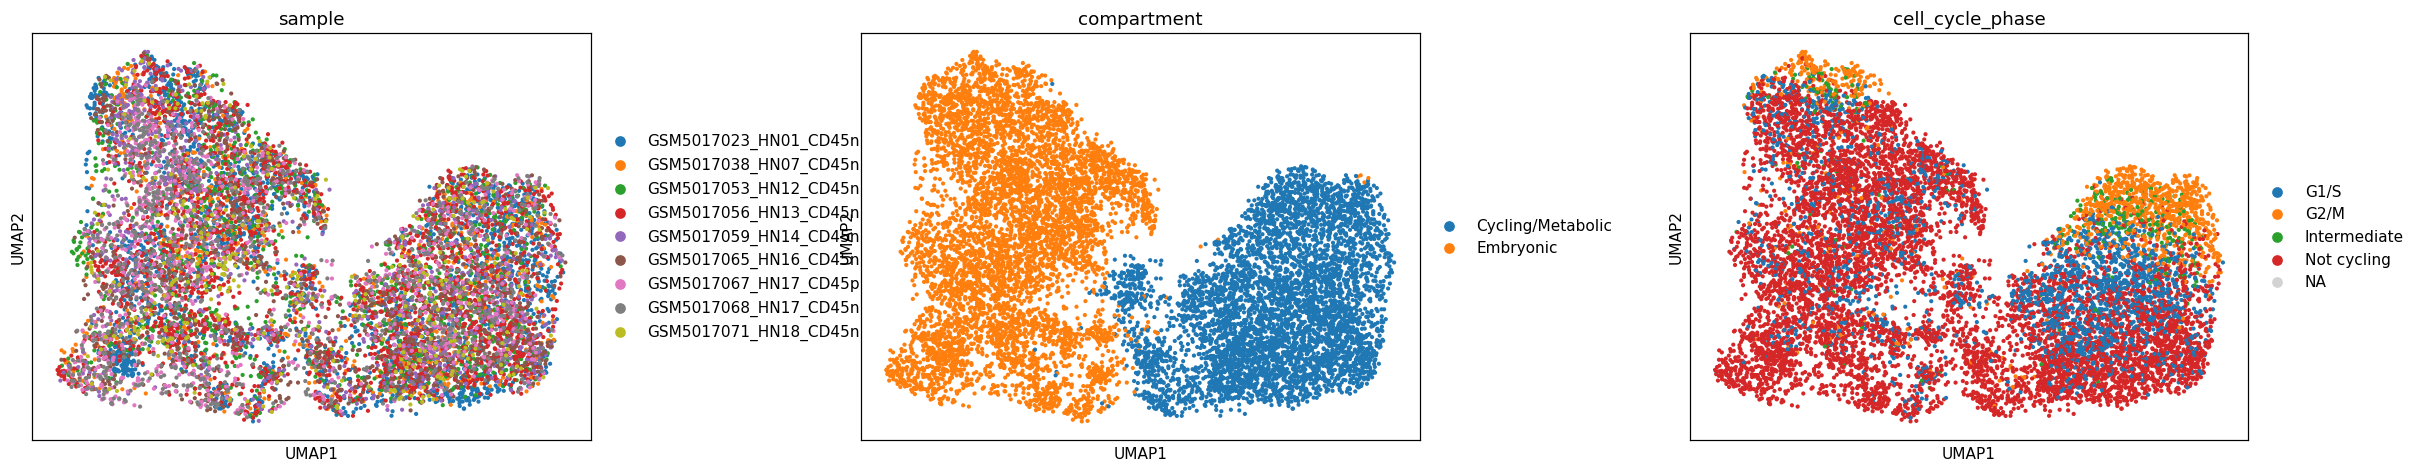

In [8]:
fig = sc.pl.umap(adata, color=['sample','compartment','cell_cycle_phase'],
                 size=30, wspace=.35, show=False)
frac_same = (adata.obs.groupby('sample', observed=True).size() > 0).mean()
n_samp = adata.obs['sample'].nunique()
print(f'{n_samp} samples share one continuous manifold; both compartments contain multiple samples.')
print('Gate 1: samples intermixed on one continuous manifold -> PASS')

### Save processed data

In [9]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (11122, 22107)


### Sample-integration figure (deliverable)

saved samples.pdf | trajectory cells: 5955


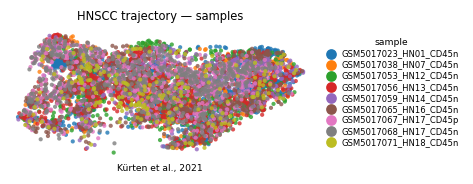

In [10]:
# Deliverable in house style (figsize=(3.5,1.5) horizontal strip, size=30) to
# match every other trajectory panel. Only the trajectory (embryonic-programme)
# cells are shown; the embryonic embedding is rotated so its major axis is
# horizontal (same strip shape as the X_umap_lin panels downstream). Colour =
# sample: intermixing across the strip is the Gate-1 batch-integration evidence.
# Orientation is not pseudotime-signed here (that axis is fixed in 02_manifold);
# direction is immaterial for this categorical panel.
traj = adata[adata.obs['compartment'] == 'Embryonic'].copy()
# Orient with the same fixed convention as every other deliverable panel: raw UMAP
# coordinates, dimension swap + y-flip -> (raw_y, -raw_x). No rotation/interpolation
# (an SVD basis can be a reflection and silently flip an axis). The trajectory's major
# axis is near-vertical in the raw embedding, so the swap makes it horizontal.
xy = traj.obsm['X_umap'].astype(float)
traj.obsm['X_umap'] = np.column_stack([xy[:,1], -xy[:,0]])
xl = traj.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(traj, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('HNSCC trajectory — samples', size=7.5)
ax.text(.5, -.12, 'Kürten et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | trajectory cells:', traj.shape[0])